# How Does the Duration of the Movie Affect the Movie IMDB Rating?
**Module 2 · Module Three Ways** &nbsp;|&nbsp; Author: **Gloria Grace** &nbsp;|&nbsp; Live page: *https://github.com/gloriagrce/courses/tree/main/data/671/Module2*

## IMDB Data

The dataset (`imdbdataset.csv`) contains 1,500 feature films with columns for title, release year, MPAA rating, run length, genres, release date, IMDb user rating (0–10), number of raters, and number of reviews. The underlying ratings come from **IMDb** (https://www.imdb.com).

**Citation:**

Verma, K. IMDb Movies Dataset [data set]. Kaggle. https://www.kaggle.com/datasets/krishnanshverma/imdb-movies-dataset

In [1]:
import pandas as pd, numpy as np
import altair as alt
import plotly.graph_objects as go
import matplotlib.pyplot as plt

## Import Data

In [2]:
# Load the Data
DATA_PATH = "https://raw.githubusercontent.com/gloriagrce/courses/refs/heads/main/data/671/Module2/imdbdataset.csv"
raw = pd.read_csv(DATA_PATH)
print("Raw rows:", len(raw))

df = raw.copy()

Raw rows: 1500


### Clean the Data

In [3]:
# 1) Remove repeated rows for the same title + year
df = df.drop_duplicates(subset=["name", "year"]).reset_index(drop=True)

# 2) Convert "2h 28min" / "2h" / "95min" into minutes
parts = df["run_length"].str.extract(r"(?:(\d+)h)?\s*(?:(\d+)min)?").astype(float).fillna(0)
df["minutes"] = parts[0] * 60 + parts[1]

# 3) Decade, and a list of genres per film
df["decade"] = (df["year"] // 10) * 10
df["genre_list"] = df["genres"].str.split(";").apply(lambda g: [x.strip() for x in g if x.strip()])

print("Unique films:", len(df))
df[["name", "year", "minutes", "genre_list", "rating", "num_raters"]].head()

Unique films: 1063


,name,year,minutes,genre_list,rating,num_raters
0,Inception,2010,148.0,"[Action, Adventure, Sci-Fi]",8.8,1981675
1,The Lord of the Rings: The Fellowship of the Ring,2001,178.0,"[Action, Adventure, Drama]",8.8,1609165
2,The Lord of the Rings: The Return of the King,2003,201.0,"[Adventure, Drama, Fantasy]",8.9,1593859
3,The Dark Knight Rises,2012,164.0,"[Action, Adventure]",8.4,1470329
4,The Lord of the Rings: The Two Towers,2002,179.0,"[Adventure, Drama, Fantasy]",8.7,1440188


In [4]:
# One row per (film, genre) - used whenever we need to group by genre
by_genre = df.explode("genre_list").rename(columns={"genre_list": "genre"})

# A coarser "era" label for colour
def era(y):
    if y < 1980: return "Before 1980"
    if y < 1990: return "1980s"
    if y < 2000: return "1990s"
    if y < 2010: return "2000s"
    return "2010s"
df["era"] = df["year"].apply(era)
by_genre["era"] = by_genre["year"].apply(era)

rho = df["minutes"].corr(df["rating"], method="spearman")
print(f"Spearman correlation between runtime and rating: {rho:.2f}")
print(df["minutes"].describe().round(0))

Spearman correlation between runtime and rating: 0.26
count    1063.0
mean      121.0
std        24.0
min        66.0
25%       104.0
50%       118.0
75%       134.0
max       271.0
Name: minutes, dtype: float64


## Visualizations

### 1. Runtime vs. rating (Altair)

In [9]:
alt.data_transformers.disable_max_rows()

films = df[["name", "year", "era", "minutes", "rating", "num_raters"]]
films_g = by_genre[["name", "genre", "minutes", "rating"]]

era_order = ["Before 1980", "1980s", "1990s", "2000s", "2010s"]
era_colors = ["#6a3d9a", "#1f78b4", "#33a02c", "#ff7f00", "#e31a1c"]

brush = alt.selection_interval(name="brush")

scatter = (
    alt.Chart(films)
    .mark_circle(size=55)
    .encode(
        x=alt.X("minutes:Q", title="Runtime (minutes)", scale=alt.Scale(domain=[60, 280])),
        y=alt.Y("rating:Q", title="IMDb rating", scale=alt.Scale(domain=[3.5, 9.5])),
        color=alt.Color("era:N", title="Release era",
                        scale=alt.Scale(domain=era_order, range=era_colors)),
        opacity=alt.condition(brush, alt.value(0.85), alt.value(0.12)),
        tooltip=[alt.Tooltip("name:N", title="Film"),
                 alt.Tooltip("year:O", title="Year"),
                 alt.Tooltip("minutes:Q", title="Minutes"),
                 alt.Tooltip("rating:Q", title="Rating")],
    )
    .add_params(brush)
    .properties(width=430, height=340,
                title="Each dot is a film: drag a box to select")
)

trend = (
    alt.Chart(films)
    .transform_regression("minutes", "rating")
    .mark_line(color="#444", strokeDash=[5, 4], size=2)
    .encode(x="minutes:Q", y="rating:Q")
)


viz1 = (scatter + trend)
viz1 = viz1.configure_axis(labelFontSize=11, titleFontSize=12, grid=True, gridOpacity=0.25) \
           .configure_title(fontSize=13, anchor="start") \
           .configure_view(stroke=None)
viz1

alt.LayerChart(...)

#### Description

To circle back to the question, by using this visualization, it is showing how
longer films does to be rated higher based on the upward slope that is present. But that does not mean it guarantees that those longer films are always rated hire. Another thing that was visible is how movies that are **longer than usual** are rarely poorly rated.

## 2. Diving Deeper into the Genre Aspect

In [6]:
bins   = [0, 90, 105, 120, 135, 150, 400]
labels = ["< 90", "90-105", "105-120", "120-135", "135-150", "150+"]
by_genre["runtime_bucket"] = pd.cut(by_genre["minutes"], bins=bins, labels=labels)

# Only genres with enough films to be meaningful
genre_counts = by_genre["genre"].value_counts()
keep = genre_counts[genre_counts >= 50].index
sub = by_genre[by_genre["genre"].isin(keep)]

avg = sub.pivot_table(index="genre", columns="runtime_bucket", values="rating",
                      aggfunc="mean", observed=False)
cnt = sub.pivot_table(index="genre", columns="runtime_bucket", values="rating",
                      aggfunc="count", observed=False).fillna(0)

# Hide tiny cells
avg = avg.where(cnt >= 4)

# Order genres by overall average rating
order = sub.groupby("genre")["rating"].mean().sort_values().index
avg, cnt = avg.loc[order], cnt.loc[order]

hover = [[f"<b>{g}</b><br>Runtime: {b} min<br>Avg rating: {avg.loc[g, b]:.2f}<br>Films: {int(cnt.loc[g, b])}"
          if not np.isnan(avg.loc[g, b]) else "" for b in avg.columns] for g in avg.index]
labels_txt = [[f"{avg.loc[g, b]:.1f}" if not np.isnan(avg.loc[g, b]) else "" for b in avg.columns]
              for g in avg.index]

fig = go.Figure(go.Heatmap(
    z=avg.values, x=list(avg.columns), y=list(avg.index),
    text=labels_txt, texttemplate="%{text}", hovertext=hover, hoverinfo="text",
    colorscale="YlGnBu", zmin=6.4, zmax=8.4, xgap=3, ygap=3,
    colorbar=dict(title="Avg<br>rating"),
))
fig.update_layout(
    title=dict(text="Within most genres, longer films are rated higher", x=0.0),
    xaxis_title="Runtime bucket (minutes)", yaxis_title=None,
    plot_bgcolor="white", width=760, height=520, font=dict(size=13),
    margin=dict(l=90, r=30, t=70, b=60),
)
fig.update_xaxes(side="bottom")
fig.show()

### Description

Based on this plot, It shows how the color are saturatedly different and slightly darker from left to right. Within some of these genres, films in the 135+ minute buckets average noticeably higher ratings than films under two hours.

## 3. Ratings Variance Within each Runtime Group

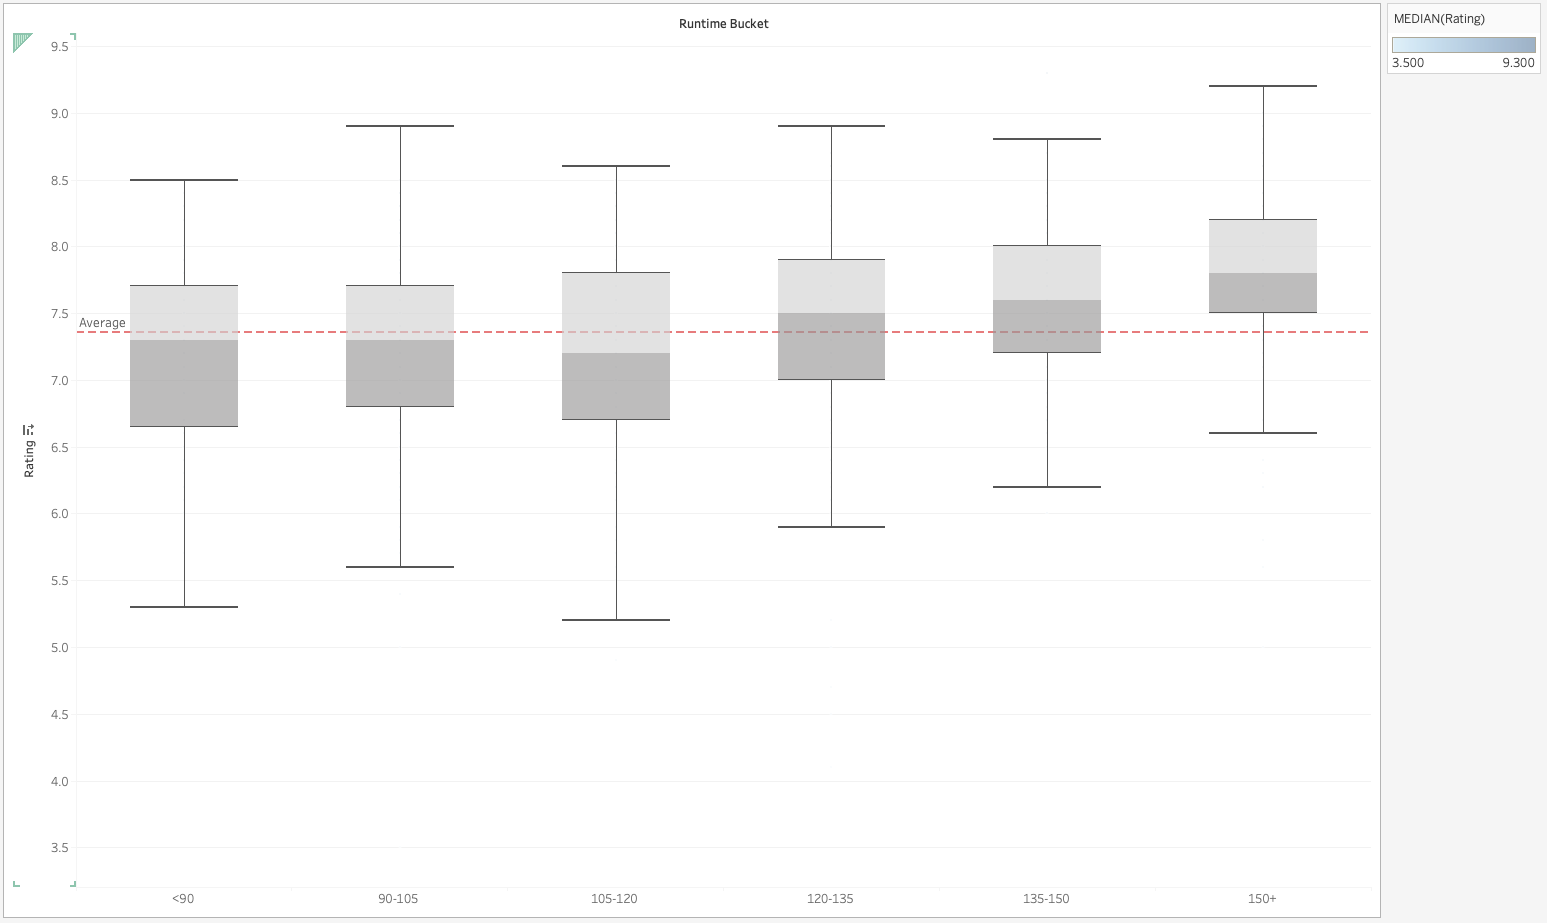

In [8]:
from PIL import Image
from IPython.display import display
import requests
from io import BytesIO

url = "https://raw.githubusercontent.com/gloriagrce/courses/main/data/671/Module2/visual3.png"

response = requests.get(url)
response.raise_for_status()

img = Image.open(BytesIO(response.content))

display(img)

### Description

Using Tableau, I design this plot to showcase how individual films might raise the whole distribution of ratings. This chart was built in **Tableau Public** from the cleaned dataset.

To help answer the central question, this plot shows how the whole distribution shifts upwards. It also shows how long movies are consistently good, not just occasionally great. In addition to this, since more movies are clustered in short and mid-length durations, it is clear how the ratings for this duration set is more varied than the long duration ones.